# Exploração 01: horário e tilt

Perguntas:

1. **Horário:** o jogador rende diferente conforme a hora do dia ou o dia da semana?
2. **Sessões:** o desempenho cai ao longo de uma sequência de partidas seguidas?
3. **Tilt:** depois de derrotas seguidas, a chance de vencer a próxima diminui?

Dados: tabela `match_participants` (uma linha por jogador por partida), preenchida pela API
e pelo script `scripts/coletar_partidas.py`.

**Definições** (questione-as!):
- Remakes ficam fora; entram Solo/Duo (420) e Flex (440).
- Horários convertidos de UTC para `America/Sao_Paulo`.
- **Sessão** = partidas com no máximo `INTERVALO_SESSAO` entre o fim de uma e o início da próxima.
- Winrates acompanhados de intervalo de confiança de 95% (Wilson): com poucas partidas, a incerteza é grande.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine, text

import sys
sys.path.insert(0, str(Path.cwd().parent))  # permite "import app" (o notebook roda em backend/notebooks)
from app.config import get_settings

# O pandas precisa de um driver síncrono: troca asyncpg por psycopg na mesma URL do .env
engine = create_engine(get_settings().database_url.replace("+asyncpg", "+psycopg"))

RIOT_ID = "Hazze Gu#hazze"
INTERVALO_SESSAO = "45 minutes"
FUSO = "America/Sao_Paulo"

plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.grid": True, "grid.alpha": 0.3})


def sql(consulta: str, **params) -> pd.DataFrame:
    return pd.read_sql(text(consulta), engine, params=params)


def wilson(vitorias, jogos, z=1.96):
    """Intervalo de confiança de 95% (Wilson) para uma proporção. Funciona com Series."""
    p = vitorias / jogos
    centro = (p + z**2 / (2 * jogos)) / (1 + z**2 / jogos)
    margem = z * np.sqrt(p * (1 - p) / jogos + z**2 / (4 * jogos**2)) / (1 + z**2 / jogos)
    return centro - margem, centro + margem


def winrate_por(df: pd.DataFrame, coluna: str, ordem: list | None = None) -> pd.DataFrame:
    """Winrate, nº de jogos e IC 95% agrupados por `coluna` (na `ordem` dada, se houver)."""
    g = df.groupby(coluna, observed=True)["win"].agg(jogos="size", vitorias="sum")
    if ordem is not None:
        g = g.loc[[o for o in ordem if o in g.index]]  # ignora categorias sem partidas
    g["winrate"] = g["vitorias"] / g["jogos"]
    g["ic_baixo"], g["ic_alto"] = wilson(g["vitorias"], g["jogos"])
    return g


def grafico_winrate(g: pd.DataFrame, titulo: str, referencia: float | None = None):
    fig, ax = plt.subplots()
    x = range(len(g))
    erro = [g["winrate"] - g["ic_baixo"], g["ic_alto"] - g["winrate"]]
    ax.bar(x, g["winrate"], yerr=erro, capsize=4, color="#3b82f6", alpha=0.8)
    for i, (wr, n) in enumerate(zip(g["winrate"], g["jogos"])):
        ax.text(i, 0.02, f"n={n}", ha="center", fontsize=8, color="white")
    if referencia is not None:
        ax.axhline(referencia, color="gray", ls="--", lw=1, label=f"média {referencia:.0%}")
        ax.legend(loc="upper right")
    ax.set_xticks(list(x), [str(i) for i in g.index])
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title(titulo)
    plt.show()

## 1. O que temos no banco

In [2]:
sql("""
    SELECT count(DISTINCT match_id)             AS partidas,
           count(*)                             AS linhas_participantes,
           count(DISTINCT puuid)                AS jogadores_distintos,
           min(game_start)::date                AS primeira,
           max(game_start)::date                AS ultima,
           pg_size_pretty(pg_total_relation_size('matches')) AS espaco_matches
    FROM match_participants
""")

,partidas,linhas_participantes,jogadores_distintos,primeira,ultima,espaco_matches
0,358,3580,3017,2026-02-15,2026-10-12,17 MB


## 2. Partidas com sessões e sequências (SQL com *window functions*)

- `LAG(fim)` traz o horário em que a partida anterior do mesmo jogador terminou.
- Uma nova sessão começa quando o intervalo passa de `INTERVALO_SESSAO`;
  `SUM(...) OVER (ORDER BY ...)` acumula essas "quebras" e vira um número de sessão.
- `ROW_NUMBER()` dentro da sessão dá a posição da partida (1ª, 2ª, 3ª...).

In [3]:
CONSULTA_PARTIDAS = """
WITH partidas AS (
    SELECT puuid, match_id, queue_id, win, champion_name, team_position,
           kills, deaths, assists, cs, game_duration,
           game_start,
           game_start + make_interval(secs => game_duration) AS fim,
           game_start AT TIME ZONE :fuso AS inicio_local
    FROM match_participants
    WHERE NOT remake AND queue_id IN (420, 440) AND puuid = ANY(:puuids)
),
com_anterior AS (
    SELECT *,
           LAG(fim) OVER (PARTITION BY puuid ORDER BY game_start) AS fim_anterior
    FROM partidas
),
com_sessao AS (
    SELECT *,
           SUM(CASE WHEN fim_anterior IS NULL
                      OR game_start - fim_anterior > CAST(:intervalo AS interval)
                    THEN 1 ELSE 0 END)
               OVER (PARTITION BY puuid ORDER BY game_start) AS sessao
    FROM com_anterior
)
SELECT *,
       ROW_NUMBER() OVER (PARTITION BY puuid, sessao ORDER BY game_start) AS jogo_na_sessao
FROM com_sessao
ORDER BY puuid, game_start
"""


def derrotas_seguidas_antes(df: pd.DataFrame) -> pd.Series:
    """Quantas derrotas seguidas o jogador vinha acumulando NA MESMA SESSÃO antes de cada partida."""
    def por_sessao(resultados: pd.Series) -> pd.Series:
        contagem, atual = [], 0
        for venceu in resultados:
            contagem.append(atual)
            atual = 0 if venceu else atual + 1
        return pd.Series(contagem, index=resultados.index)
    return df.groupby(["puuid", "sessao"], group_keys=False)["win"].apply(por_sessao)


def carregar(puuids: list[str]) -> pd.DataFrame:
    df = sql(CONSULTA_PARTIDAS, puuids=puuids, fuso=FUSO, intervalo=INTERVALO_SESSAO)
    df["hora"] = df["inicio_local"].dt.hour
    df["periodo"] = pd.cut(
        df["hora"], bins=[-1, 5, 11, 17, 23],
        labels=["Madrugada (0-5h)", "Manhã (6-11h)", "Tarde (12-17h)", "Noite (18-23h)"],
    )
    dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
    df["dia_semana"] = pd.Categorical(df["inicio_local"].dt.dayofweek.map(dict(enumerate(dias))), dias, ordered=True)
    df["fim_de_semana"] = df["inicio_local"].dt.dayofweek >= 5
    df["derrotas_antes"] = derrotas_seguidas_antes(df)
    return df

## 3. Você (o jogador definido em `RIOT_ID`)

In [4]:
nome, tag = RIOT_ID.split("#")
meu_puuid = sql(
    "SELECT puuid FROM accounts WHERE lower(game_name) = lower(:n) AND lower(tag_line) = lower(:t)",
    n=nome, t=tag,
)["puuid"].iloc[0]

eu = carregar([meu_puuid])
media = eu["win"].mean()
print(f"{len(eu)} partidas de {eu['inicio_local'].min():%d/%m/%Y} a {eu['inicio_local'].max():%d/%m/%Y}")
print(f"Winrate geral: {media:.1%} | sessões: {eu['sessao'].nunique()} | "
      f"partidas por sessão (média): {eu.groupby('sessao').size().mean():.1f}")

290 partidas de 15/02/2026 a 12/10/2026
Winrate geral: 52.1% | sessões: 108 | partidas por sessão (média): 2.7


### 3.1 Horário

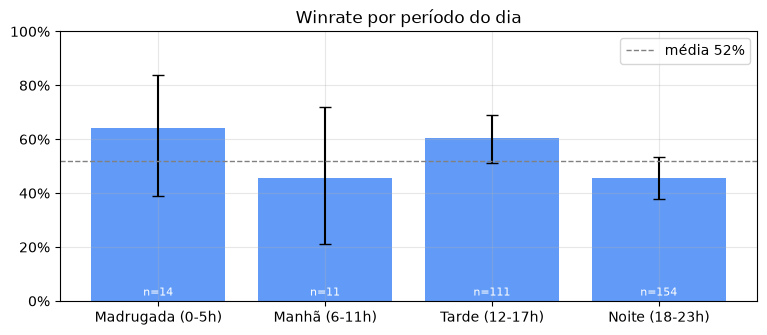

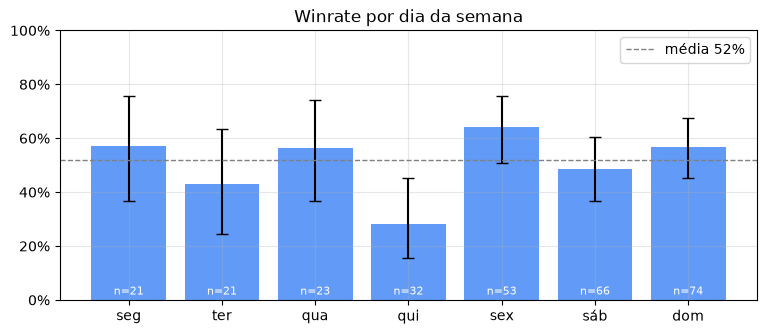

In [5]:
grafico_winrate(winrate_por(eu, "periodo"), "Winrate por período do dia", media)
grafico_winrate(winrate_por(eu, "dia_semana"), "Winrate por dia da semana", media)

### 3.2 Posição na sessão
A 1ª partida do dia rende diferente da 5ª? Agrupamos a partir da 5ª para não ficar com grupos minúsculos.

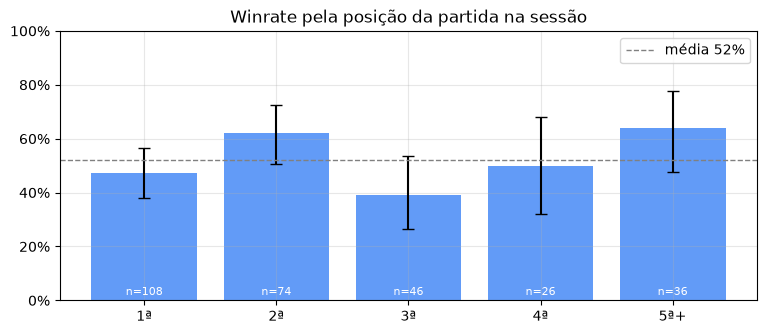

In [6]:
eu["posicao"] = eu["jogo_na_sessao"].clip(upper=5).map(lambda n: f"{n}ª" if n < 5 else "5ª+")
grafico_winrate(winrate_por(eu, "posicao", ["1ª", "2ª", "3ª", "4ª", "5ª+"]), "Winrate pela posição da partida na sessão", media)

### 3.3 Tilt: winrate depois de derrotas seguidas (na mesma sessão)
`0` = vinha de vitória ou é a 1ª partida da sessão; `1` = vinha de 1 derrota; `2+` = 2 ou mais derrotas seguidas.

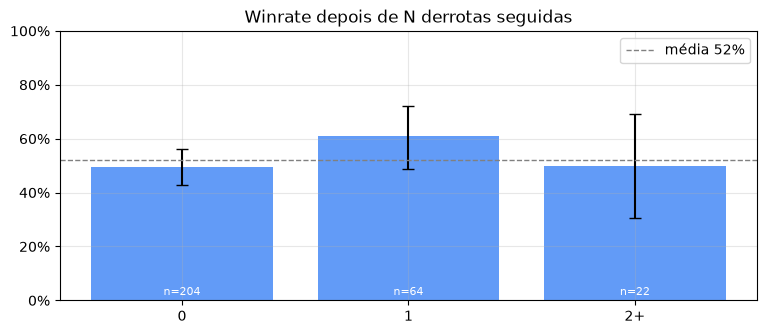

,jogos,vitorias,winrate,ic_baixo,ic_alto
sequencia,,,,,
0,204,101,0.495098,0.427215,0.563162
1,64,39,0.609375,0.486917,0.719446
2+,22,11,0.500000,0.307218,0.692782


In [7]:
eu["sequencia"] = eu["derrotas_antes"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"})
grafico_winrate(winrate_por(eu, "sequencia", ["0", "1", "2+"]), "Winrate depois de N derrotas seguidas", media)
winrate_por(eu, "sequencia", ["0", "1", "2+"])

## 4. Amostra: jogadores de todos os elos

Para comparar jogadores diferentes de forma justa, medimos o **desvio em relação ao winrate do
próprio jogador** (ex.: "+3 p.p. à noite"). Sem isso, o resultado mistura *quem* joga em cada
horário com *como* cada um joga naquele horário.

In [8]:
caminho_amostra = Path.cwd().parent / "dados" / "amostra_jogadores.json"
amostra = json.loads(caminho_amostra.read_text(encoding="utf-8")) if caminho_amostra.exists() else []
tier_de = {j["puuid"]: j["tier"] for j in amostra}

todos = carregar(list(tier_de))
todos["tier"] = todos["puuid"].map(tier_de)
todos["desvio"] = todos["win"] - todos.groupby("puuid")["win"].transform("mean")

partidas_por_jogador = todos.groupby("puuid").size()
print(f"{len(todos)} partidas de {todos['puuid'].nunique()} jogadores "
      f"(mediana de {partidas_por_jogador.median():.0f} partidas por jogador)")
todos.groupby("tier").agg(jogadores=("puuid", "nunique"), partidas=("match_id", "size"))

50 partidas de 1 jogadores (mediana de 50 partidas por jogador)


,jogadores,partidas
tier,,
IRON,1,50


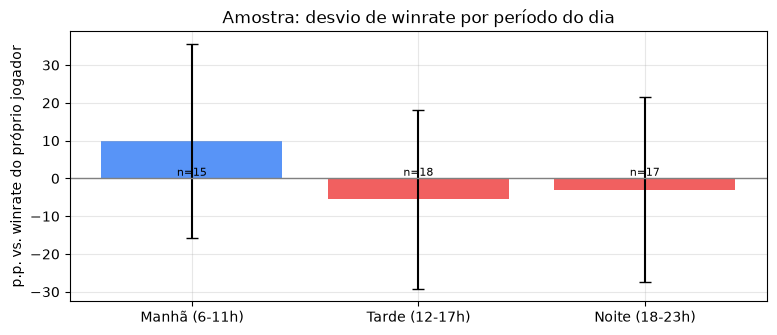

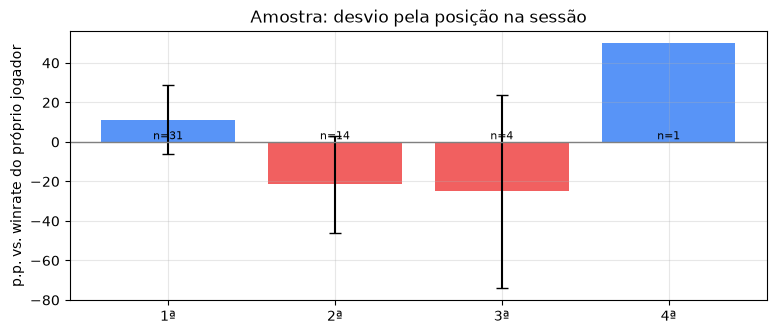

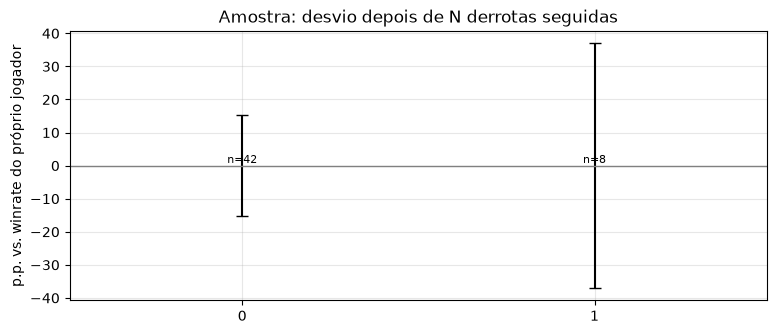

In [9]:
def grafico_desvio(df: pd.DataFrame, coluna: str, titulo: str, ordem=None):
    g = df.groupby(coluna, observed=True)["desvio"].agg(["mean", "sem", "size"])
    if ordem is not None:
        g = g.loc[[o for o in ordem if o in g.index]]
    fig, ax = plt.subplots()
    x = range(len(g))
    ax.bar(x, g["mean"] * 100, yerr=1.96 * g["sem"] * 100, capsize=4,
           color=["#ef4444" if v < 0 else "#3b82f6" for v in g["mean"]], alpha=0.85)
    for i, n in enumerate(g["size"]):
        ax.text(i, 0, f"n={n}", ha="center", va="bottom", fontsize=8)
    ax.axhline(0, color="gray", lw=1)
    ax.set_xticks(list(x), [str(i) for i in g.index])
    ax.set_ylabel("p.p. vs. winrate do próprio jogador")
    ax.set_title(titulo)
    plt.show()

if len(todos):
    todos["posicao"] = todos["jogo_na_sessao"].clip(upper=5).map(lambda n: f"{n}ª" if n < 5 else "5ª+")
    todos["sequencia"] = todos["derrotas_antes"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
    grafico_desvio(todos, "periodo", "Amostra: desvio de winrate por período do dia")
    grafico_desvio(todos, "posicao", "Amostra: desvio pela posição na sessão", ["1ª", "2ª", "3ª", "4ª", "5ª+"])
    grafico_desvio(todos, "sequencia", "Amostra: desvio depois de N derrotas seguidas", ["0", "1", "2", "3+"])

## 5. Anotações e próximas perguntas

- Atenção ao viés de seleção: só vemos as partidas que a pessoa **decidiu** jogar. Quem para
  depois de 2 derrotas some da estatística "depois de 3 derrotas".
- Regressão logística (`win ~ derrotas_antes + posicao + periodo + efeito fixo do jogador`) para
  separar os efeitos que hoje aparecem misturados.
- A duração da sessão em minutos pode explicar melhor que o número de partidas.
- O tilt aparece em métricas além da vitória? (mortes, KDA, CS/min depois de derrotas)